In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [2]:
df = pd.read_csv("../data/Student_perf.csv")

df.shape

(50, 9)

In [ ]:
print("Dataset shape:", df.shape)
print("Duplicates:", df.duplicated().sum())

Dataset shape: (50, 9)
Duplicates: 0


In [7]:
print("Missing Values:")
print(df.isna().sum())

Missing Values:
Student_ID              0
Program                 0
Year_Level              0
Attendance_Pct          1
Study_Hours_Per_Week    1
Assignment_Avg          1
Previous_Exam_Score     1
Final_Score             0
Risk_Label              0
dtype: int64


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            50 non-null     str    
 1   Program               50 non-null     str    
 2   Year_Level            50 non-null     str    
 3   Attendance_Pct        49 non-null     float64
 4   Study_Hours_Per_Week  49 non-null     float64
 5   Assignment_Avg        49 non-null     float64
 6   Previous_Exam_Score   49 non-null     float64
 7   Final_Score           50 non-null     int64  
 8   Risk_Label            50 non-null     str    
dtypes: float64(4), int64(1), str(4)
memory usage: 3.6 KB


In [9]:
df.describe()

,Attendance_Pct,Study_Hours_Per_Week,Assignment_Avg,Previous_Exam_Score,Final_Score
count,49.000000,49.000000,49.000000,49.000000,50.000000
mean,79.469388,5.061224,78.551020,75.387755,69.740000
std,13.856560,2.577209,12.571564,13.071624,13.621427
min,52.000000,0.000000,51.000000,52.000000,44.000000
25%,69.000000,3.000000,70.000000,64.000000,59.000000
50%,81.000000,5.000000,78.000000,78.000000,68.500000
75%,90.000000,7.000000,87.000000,85.000000,78.000000
max,101.000000,10.000000,97.000000,94.000000,96.000000


In [10]:
print(df.columns.tolist())

['Student_ID', 'Program', 'Year_Level', 'Attendance_Pct', 'Study_Hours_Per_Week', 'Assignment_Avg', 'Previous_Exam_Score', 'Final_Score', 'Risk_Label']


In [11]:
print(df.shape)
print(df.columns.tolist())
print(df.isna().sum())

(50, 9)
['Student_ID', 'Program', 'Year_Level', 'Attendance_Pct', 'Study_Hours_Per_Week', 'Assignment_Avg', 'Previous_Exam_Score', 'Final_Score', 'Risk_Label']
Student_ID              0
Program                 0
Year_Level              0
Attendance_Pct          1
Study_Hours_Per_Week    1
Assignment_Avg          1
Previous_Exam_Score     1
Final_Score             0
Risk_Label              0
dtype: int64


In [12]:
missing_rows  = df[df.isna().any(axis=1)]

print(missing_rows.to_string(index=False))

Student_ID Program Year_Level  Attendance_Pct  Study_Hours_Per_Week  Assignment_Avg  Previous_Exam_Score  Final_Score  Risk_Label
      S004    BSIT        4th            64.0                   NaN            66.0                 60.0           59     At Risk
      S015    BSCS        3rd             NaN                   6.0            87.0                 85.0           76 Not At Risk
      S028    BSIS        4th            52.0                   1.0             NaN                 52.0           45     At Risk
      S040    BSCS        4th            77.0                   5.0            78.0                  NaN           66     At Risk


In [13]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [14]:
print("\nRisk group counts:")
print(df["Risk_Label"].value_counts())


Risk group counts:
Risk_Label
At Risk        27
Not At Risk    23
Name: count, dtype: int64


In [15]:
print("\nRisk group percentages:")
print(
    df["Risk_Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Risk group percentages:
Risk_Label
At Risk        54.0
Not At Risk    46.0
Name: proportion, dtype: float64


In [16]:
clean = df.copy()

clean["Study_Hours_Per_Week"] = (
    clean["Study_Hours_Per_Week"]
    .fillna(clean["Study_Hours_Per_Week"].median())
)

In [18]:
columns_to_compare = [
    "Attendance_Pct",
    "Study_Hours_Per_Week",
    "Assignment_Avg",
    "Previous_Exam_Score",
    "Final_Score"
]

risk_comparison = (
    df.groupby("Risk_Label")[columns_to_compare]
    .mean()
    .round(2)
)

print(risk_comparison)

             Attendance_Pct  Study_Hours_Per_Week  Assignment_Avg  \
Risk_Label                                                          
At Risk               70.22                  3.15           69.35   
Not At Risk           90.82                  7.22           88.96   

             Previous_Exam_Score  Final_Score  
Risk_Label                                     
At Risk                    65.58        59.56  
Not At Risk                86.48        81.70  


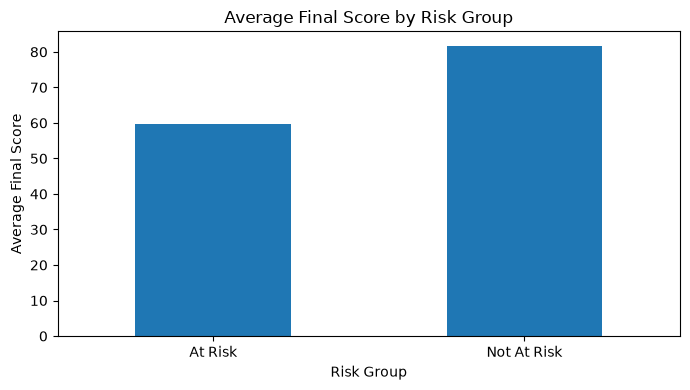

In [ ]:
import matplotlib.pyplot as plt

final_scores = df.groupby("Risk_Label")["Final_Score"].mean()

final_scores.plot(kind="bar", figsize=(7,4))

plt.title("Average Final Score by Risk Group")
plt.xlabel("Risk Group")
plt.ylabel("Average Final Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#The Not At Risk group had an average final score of 81.70, compared
#with 59.56 for At Risk group, a difference of 22.14 points.

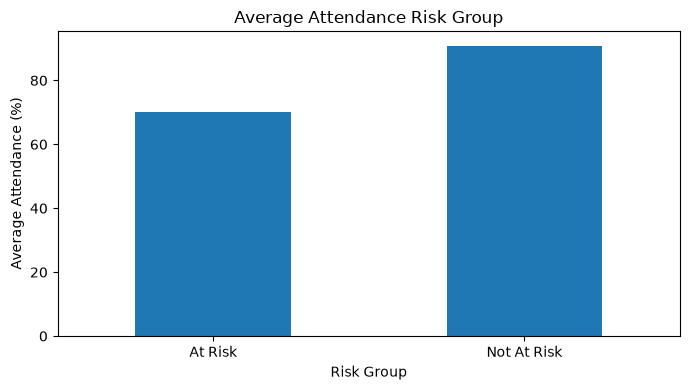

In [ ]:
attendance = df.groupby("Risk_Label")["Attendance_Pct"].mean()

attendance.plot(kind="bar", figsize=(7, 4))

plt.title("Average Attendance Risk Group")
plt.xlabel("Risk Group")
plt.ylabel("Average Attendance (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#Average attendance was 90.82% for the Not At Risk group and 70.22% for
#the At Risk group, a difference of 20.60 percentange points

In [23]:
numeric_cols = [
    "Attendance_Pct",
    "Study_Hours_Per_Week",
    "Assignment_Avg",
    "Previous_Exam_Score",
    "Final_Score"
]

correlations = (
    df[numeric_cols]
    .corr()["Final_Score"]
    .drop("Final_Score")
    .sort_values(ascending=False)
)

print(correlations.round(3))

Assignment_Avg          0.973
Previous_Exam_Score     0.973
Study_Hours_Per_Week    0.954
Attendance_Pct          0.936
Name: Final_Score, dtype: float64


In [26]:
clean = df.copy()

print("Missing values before cleaning:")
print(clean.isna().sum())

duplicates = df.duplicated().sum
print("\nExact duplicate rows:", duplicates)

clean = clean.drop_duplicates().copy()

numeric_cols = [
    "Attendance_Pct",
    "Study_Hours_Per_Week",
    "Assignment_Avg",
    "Previous_Exam_Score"
]

for col in numeric_cols:
    clean[col] = clean[col].fillna(clean[col].median())
    
    print("\nMissing values after cleaning:")
    print(clean.isna().sum())
    
    print("\nFinal dataset shape:", clean.shape)

Missing values before cleaning:
Student_ID              0
Program                 0
Year_Level              0
Attendance_Pct          1
Study_Hours_Per_Week    1
Assignment_Avg          1
Previous_Exam_Score     1
Final_Score             0
Risk_Label              0
dtype: int64

Exact duplicate rows: <bound method Series.sum of 0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39    False
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47    False
48    False
49    False
dtype: bool>

Missing values after cleaning:
Student_ID              0

In [27]:
program_scores = (
    clean.groupby("Program")["Final_Score"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average Final Score by Program:")
print(program_scores)

Average Final Score by Program:
Program
BSIT    75.75
BSCS    69.60
BSIS    58.00
Name: Final_Score, dtype: float64


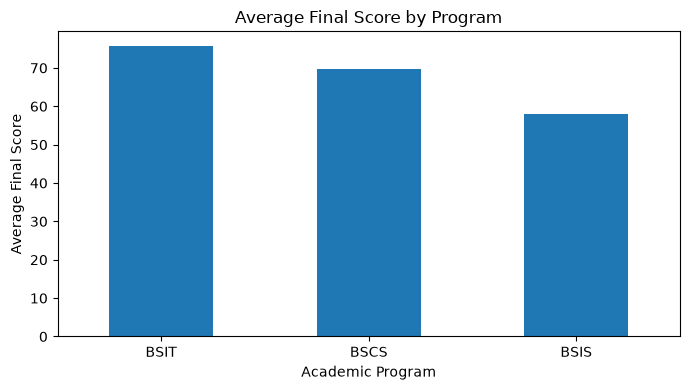

In [ ]:
program_scores.plot(kind="bar", figsize=(7, 4))

import matplotlib.pyplot as plt

plt.title("Average Final Score by Program")
plt.xlabel("Academic Program")
plt.ylabel("Average Final Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#BSIT recorded the highest average final score (75.75), followed by BSCS (69.60) and BSIS (58.00). 
#The 17.75-point difference between BSIT and BSIS suggests that it would be useful to investigate 
# whether academic support needs or other relevant factors differ across programs.

In [29]:
year_scores = (
    clean.groupby("Year_Level")["Final_Score"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average Final Score by Year Level:")
print(year_scores)

Average Final Score by Year Level:
Year_Level
1st    78.69
3rd    74.67
2nd    64.38
4th    60.92
Name: Final_Score, dtype: float64


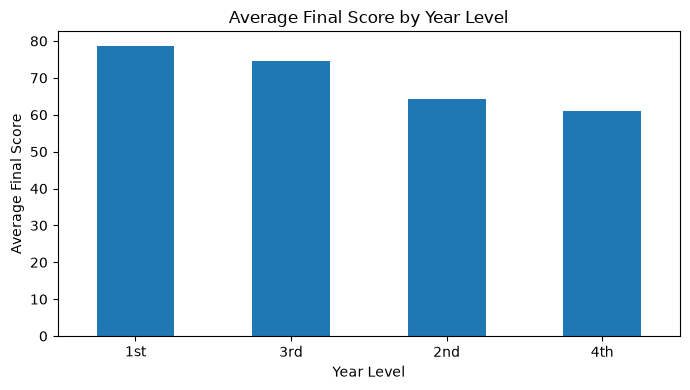

In [32]:
year_scores.plot(kind="bar", figsize=(7, 4))

import matplotlib.pyplot as plt

plt.title("Average Final Score by Year Level")
plt.xlabel("Year Level")
plt.ylabel("Average Final Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
risk_by_program = pd.crosstab(
    clean["Program"],
    clean["Risk_Label"],
    normalize="index"
) * 100

print("Risk percentage by program:")
print(risk_by_program.round(2))

Risk percentage by program:
Risk_Label  At Risk  Not At Risk
Program                         
BSCS           50.0         50.0
BSIS           70.0         30.0
BSIT           50.0         50.0


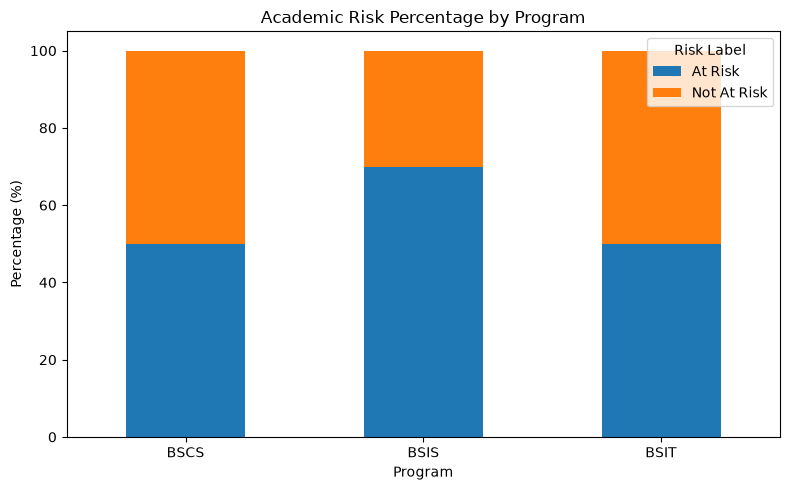

In [34]:
import matplotlib.pyplot as plt

risk_by_program.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Academic Risk Percentage by Program")
plt.xlabel("Program")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Risk Label")
plt.tight_layout()
plt.show()

In [35]:
numeric_data = clean.select_dtypes(include="number")

statistics = numeric_data.agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

print("Descriptive Statistics")
print(statistics.round(2).to_string())

Descriptive Statistics
                       mean  median    std   min    max
Attendance_Pct        79.50    81.0  13.72  52.0  101.0
Study_Hours_Per_Week   5.06     5.0   2.55   0.0   10.0
Assignment_Avg        78.54    78.0  12.44  51.0   97.0
Previous_Exam_Score   75.44    78.0  12.94  52.0   94.0
Final_Score           69.74    68.5  13.62  44.0   96.0


In [36]:
# Find invalid attendance percentages
invalid_attendance = clean[
    (clean["Attendance_Pct"] < 0) |
    (clean["Attendance_Pct"] > 100)
]

print("INVALID ATTENDANCE RECORDS")
print(invalid_attendance.to_string(index=False))

print("Total invalid records:", len(invalid_attendance))


INVALID ATTENDANCE RECORDS
Student_ID Program Year_Level  Attendance_Pct  Study_Hours_Per_Week  Assignment_Avg  Previous_Exam_Score  Final_Score  Risk_Label
      S009    BSIT        1st           101.0                   8.0            97.0                 94.0           93 Not At Risk
Total invalid records: 1


In [37]:
clean.loc[
    (clean["Attendance_Pct"] < 0) |
    (clean["Attendance_Pct"] > 100),
    "Attendance_Pct"
] = float("nan")

valid_median = clean["Attendance_Pct"].median()

clean["Attendance_Pct"] = clean["Attendance_Pct"].fillna(valid_median)

print("Median used:", valid_median)
print("New maximum:", clean["Attendance_Pct"].max())

print("Remaining invalid attendance:",
      ((clean["Attendance_Pct"] < 0) |
       (clean["Attendance_Pct"] > 100)).sum())


Median used: 81.0
New maximum: 100.0
Remaining invalid attendance: 0


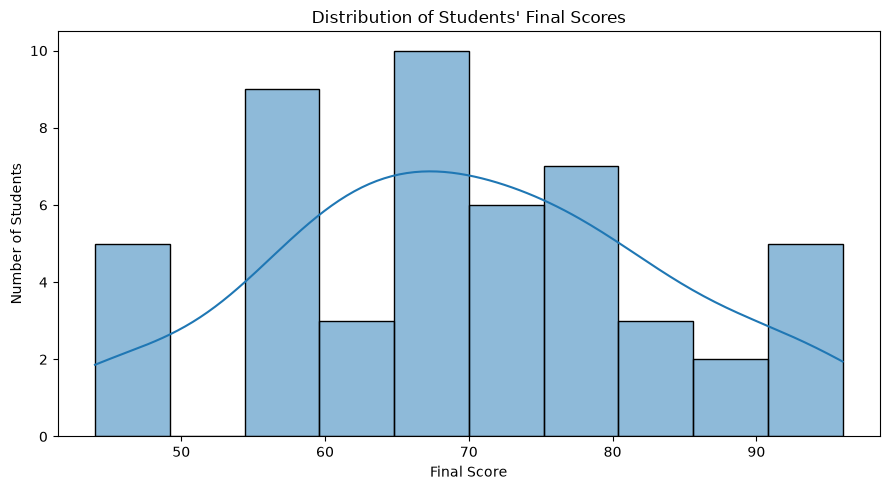

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean,
    x="Final_Score",
    bins=10,
    kde=True
)

plt.title("Distribution of Students' Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig("final_score_distribution.png", dpi=300)
plt.show()


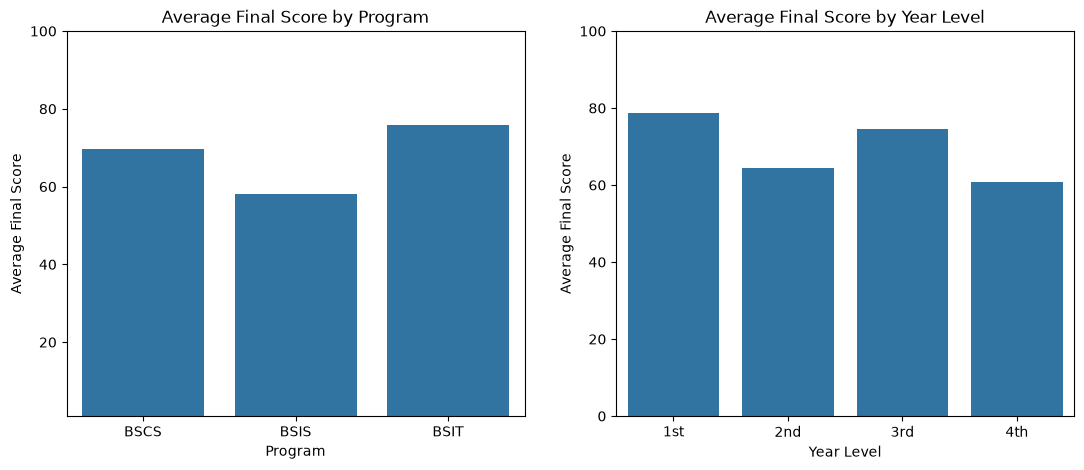

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=clean,
    x="Program",
    y="Final_Score",
    order=["BSCS", "BSIS", "BSIT"],
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Average Final Score by Program")
axes[0].set_xlabel("Program")
axes[0].set_ylabel("Average Final Score")
axes[0].set_ylim(1,100)


sns.barplot(
    data=clean,
    x="Year_Level",
    y="Final_Score",
    order=["1st", "2nd", "3rd", "4th"],
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Average Final Score by Year Level")
axes[1].set_xlabel("Year Level")
axes[1].set_ylabel("Average Final Score")
axes[1].set_ylim(0, 100)

plt.tight_layout
plt.savefig("average_final_scores.png", dpi=300)
plt.show()

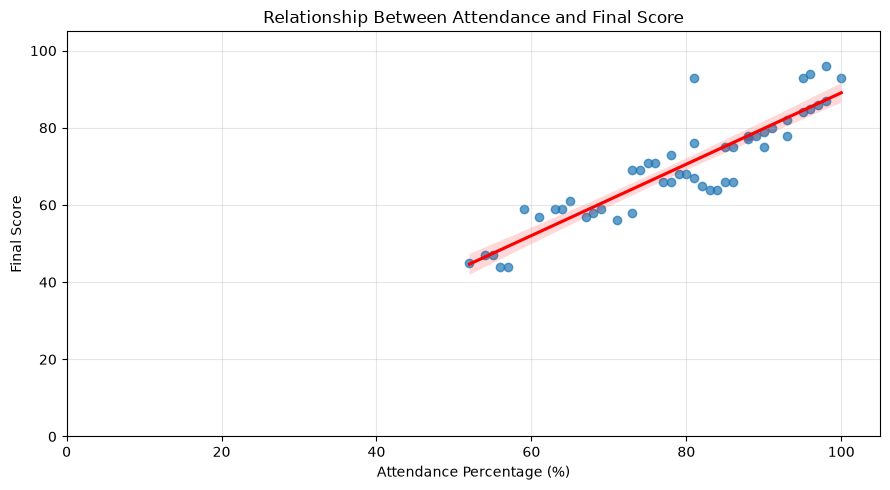

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.regplot(
    data=clean,
    x="Attendance_Pct",
    y="Final_Score",
    scatter_kws={"alpha": 0.7 },
    line_kws={"color": "red"}
)

plt.title("Relationship Between Attendance and Final Score")
plt.xlabel("Attendance Percentage (%)")
plt.ylabel("Final Score")

plt.xlim(0, 105)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("attendance_vs_final_score.png", dpi=300)
plt.show()

In [51]:
predictors = [
    "Attendance_Pct",
    "Study_Hours_Per_Week",
    "Assignment_Avg",
    "Previous_Exam_Score"
]

correlations = clean[
    predictors + ["Final_Score"]
].corr()["Final_Score"].drop("Final_Score")

print("CORRELATION WITH FINAL SCORE")
print(correlations.sort_values(ascending=False).round(3))

CORRELATION WITH FINAL SCORE
Previous_Exam_Score     0.970
Study_Hours_Per_Week    0.948
Assignment_Avg          0.941
Attendance_Pct          0.908
Name: Final_Score, dtype: float64


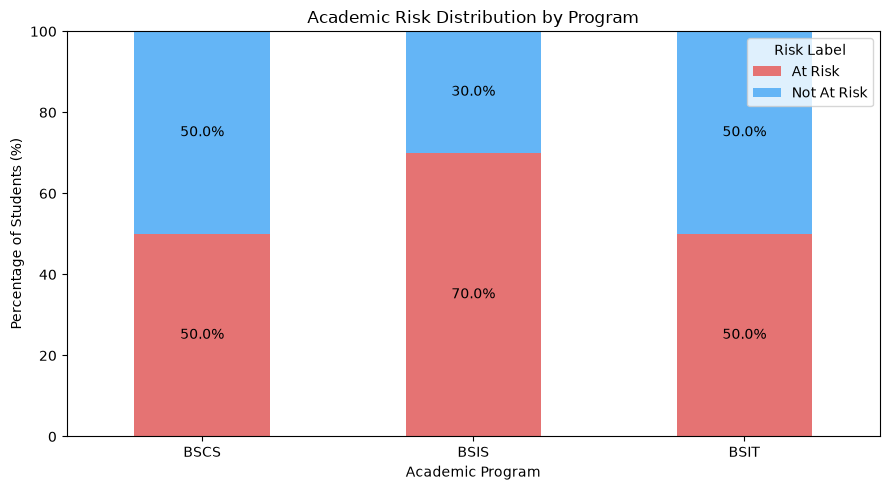

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

risk_percent = pd.crosstab(
    clean["Program"],
    clean["Risk_Label"],
    normalize="index"
) * 100

risk_percent = risk_percent.reindex(
    columns=["At Risk", "Not At Risk"]
)

ax = risk_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#E57373", "#64B5F6"]
)

plt.title("Academic Risk Distribution by Program")
plt.xlabel("Academic Program")
plt.ylabel("Percentage of Students (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Risk Label")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center"
    )

plt.tight_layout()
plt.savefig("risk_distribution_by_program.png", dpi=300)
plt.show()
